<a href="https://colab.research.google.com/github/ummugulsumciftci/GROUP30_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os, sys, subprocess

GITHUB_USER = "ummugulsumciftci"
REPO_DIR = "GROUP30_CENG313"
REPO_PATH = f"/content/{REPO_DIR}"

if not os.path.exists(REPO_PATH):
    url = f"https://github.com/{GITHUB_USER}/{REPO_DIR}.git"
    try:  # private repo -> token from Colab secrets
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{GITHUB_USER}/{REPO_DIR}.git"
    except Exception:
        pass  # public repo
    subprocess.run(["git", "clone", "-q", url, REPO_PATH], check=True)
else:
    subprocess.run(["git", "pull", "-q"], cwd=REPO_PATH)  # get the latest src/ changes

os.chdir(REPO_PATH)
sys.path.insert(0, REPO_PATH)
!pip install -q pymupdf
print("src files:", os.listdir("src"))

src files: ['data.py', '__init__.py', 'models.py', 'utils.py']


In [3]:
#data load
import os

if not os.path.exists("/content/data/train_labels.csv"):
    from google.colab import files
    uploaded = files.upload()                        # choose kaggle.json
    fname = list(uploaded.keys())[0]                 # real name, e.g. "kaggle (1).json"
    os.makedirs("/root/.kaggle", exist_ok=True)
    os.replace(fname, "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    !kaggle competitions download -c make-data-count-finding-data-references -p /content
    !unzip -q -o /content/make-data-count-finding-data-references.zip -d /content/data
print(os.listdir("/content/data"))

Saving kaggle (1).json to kaggle (1).json
100% 1.76G/1.76G [00:19<00:00, 97.4MB/s]

['sample_submission.csv', 'test', 'train_labels.csv', 'train']


In [4]:
#settings
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from src.data import Paths, find_data_dir, load_labels, scored_labels, list_articles, load_texts, reference_start
from src.utils import build_candidates, attach_gold, doi_prefix, accession_family, set_seed

set_seed(42)
pd.set_option("display.max_colwidth", 120)

# one colour per meaning, used in every chart
C = {"Primary": "#2a78d6", "Secondary": "#eb6834", "None": "#9a9890", "bar": "#2a78d6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110, "axes.titleweight": "bold"})

paths = Paths(find_data_dir())
print("data dir:", paths.root)

data dir: /content/data


In [5]:
train_art = list_articles(paths, "train")
test_art = list_articles(paths, "test")
inv = pd.DataFrame({
    split: {"articles": len(a), "with PDF": int(a.has_pdf.sum()), "with XML": int(a.has_xml.sum()),
            "PDF and XML": int((a.has_pdf & a.has_xml).sum())}
    for split, a in [("train", train_art), ("test", test_art)]})
inv

,train,test
articles,524,30
with PDF,524,30
with XML,400,25
PDF and XML,400,25


In [6]:
labels = load_labels(paths)
gold = scored_labels(labels)            # rows used by the metric (no 'Missing')
print("label rows:", len(labels), "| articles in labels:", labels.article_id.nunique())
print("scored tuples (without Missing):", len(gold))
labels.head(10)

label rows: 1066 | articles in labels: 523
scored tuples (without Missing): 719


,article_id,dataset_id,type,dataset_id_raw,is_missing,id_kind
0,10.1002_2017jc013030,https://doi.org/10.17882/49388,Primary,https://doi.org/10.17882/49388,False,DOI
1,10.1002_anie.201916483,https://doi.org/10.5517/ccdc.csd.cc1npvt0,Missing,https://doi.org/10.5517/ccdc.csd.cc1npvt0,True,Missing
2,10.1002_anie.202005531,https://doi.org/10.5517/ccdc.csd.cc24wxqp,Missing,https://doi.org/10.5517/ccdc.csd.cc24wxqp,True,Missing
3,10.1002_anie.202007717,https://doi.org/10.5517/ccdc.csd.cc24rrb0,Missing,https://doi.org/10.5517/ccdc.csd.cc24rrb0,True,Missing
4,10.1002_chem.201902131,https://doi.org/10.5517/ccdc.csd.cc221dk3,Missing,https://doi.org/10.5517/ccdc.csd.cc221dk3,True,Missing
5,10.1002_chem.201903120,https://doi.org/10.5517/ccdc.csd.cc22c4yk,Missing,https://doi.org/10.5517/ccdc.csd.cc22c4yk,True,Missing
6,10.1002_chem.202000235,https://doi.org/10.5517/ccdc.csd.cc24cjxz,Missing,https://doi.org/10.5517/ccdc.csd.cc24cjxz,True,Missing
7,10.1002_chem.202001412,https://doi.org/10.5517/ccdc.csd.cc24nsk5,Missing,https://doi.org/10.5517/ccdc.csd.cc24nsk5,True,Missing
8,10.1002_chem.202001412,https://doi.org/10.5517/ccdc.csd.cc24nsqb,Missing,https://doi.org/10.5517/ccdc.csd.cc24nsqb,True,Missing
9,10.1002_chem.202001668,https://doi.org/10.5517/ccdc.csd.cc24d93z,Missing,https://doi.org/10.5517/ccdc.csd.cc24d93z,True,Missing


In [7]:
art_status = labels.groupby("article_id")["is_missing"].all().map({True: "no dataset (Missing)", False: ">=1 dataset"})
print(art_status.value_counts(), "\n")
print(gold["type"].value_counts(), "\n")
print("PDFs without any label row:", len(set(train_art.article_id) - set(labels.article_id)))
print("same (article, dataset) with two different types:", gold.duplicated(["article_id", "dataset_id"], keep=False).sum())

is_missing
no dataset (Missing)    309
>=1 dataset             214
Name: count, dtype: int64 

type
Secondary    449
Primary      270
Name: count, dtype: int64 

PDFs without any label row: 1
same (article, dataset) with two different types: 0


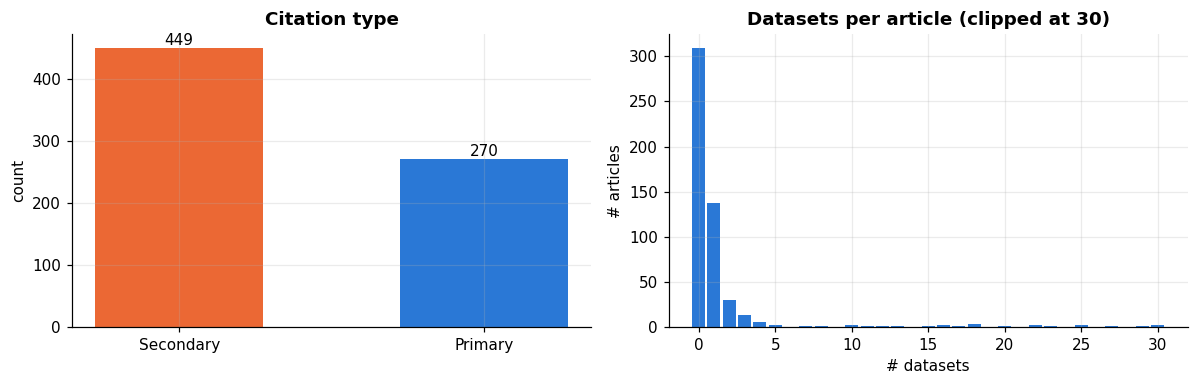

count    523.00
mean       1.37
std        4.15
min        0.00
25%        0.00
50%        0.00
75%        1.00
max       32.00
dtype: float64


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = gold["type"].value_counts()
ax[0].bar(vc.index, vc.values, color=[C[t] for t in vc.index], width=.55)
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v}", ha="center", va="bottom")
ax[0].set_title("Citation type"); ax[0].set_ylabel("count")

per_art = gold.groupby("article_id").size().reindex(labels.article_id.unique(), fill_value=0)
bins = np.arange(0, min(per_art.max(), 30) + 2) - .5
ax[1].hist(per_art.clip(upper=30), bins=bins, color=C["bar"], rwidth=.85)
ax[1].set_title("Datasets per article (clipped at 30)"); ax[1].set_xlabel("# datasets"); ax[1].set_ylabel("# articles")
plt.tight_layout(); plt.show()
print(per_art.describe().round(2))

type,Primary,Secondary
id_kind,,
Accession,55,339
DOI,215,110


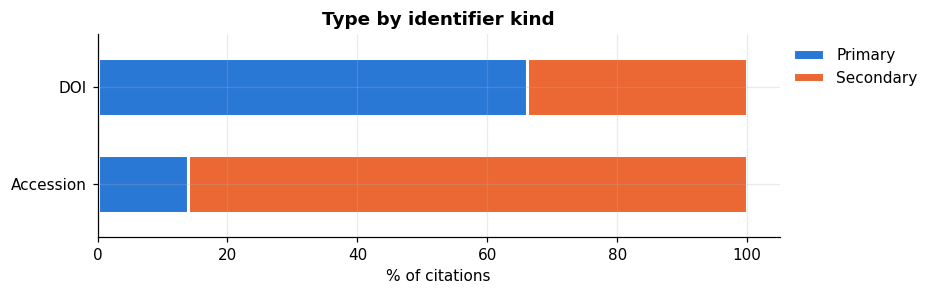

In [9]:
gold["id_kind"] = np.where(gold.dataset_id.str.contains(r"10\.\d{4,9}/"), "DOI", "Accession")
ct = pd.crosstab(gold.id_kind, gold.type)
display(ct)

ax = (ct.div(ct.sum(1), axis=0) * 100).plot.barh(stacked=True, figsize=(8, 2.4),
        color=[C[c] for c in ct.columns], width=.6, edgecolor="white", linewidth=2)
ax.set_xlabel("% of citations"); ax.set_ylabel(""); ax.set_title("Type by identifier kind")
ax.legend(frameon=False, bbox_to_anchor=(1, 1)); plt.show()

distinct DOI prefixes: 49


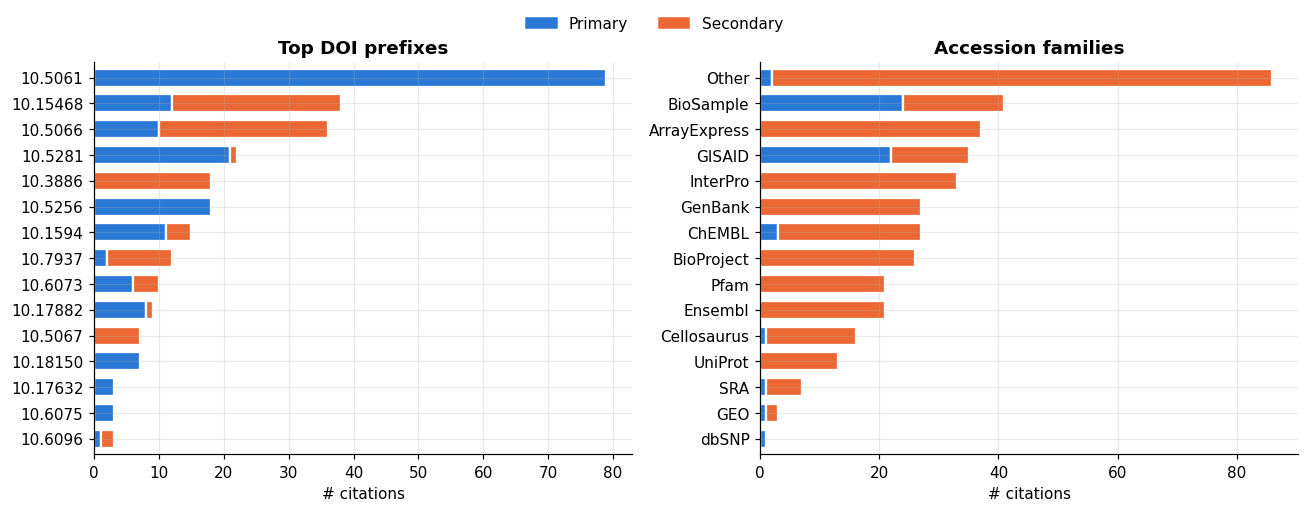

accessions not matched by our regexes: 86


,article_id,dataset_id,type,id_kind,family
40,10.1021_acsomega.3c06074,5VA1,Secondary,Accession,Other
50,10.1021_acsomega.3c06074,CHEMBL70,Secondary,Accession,Other
111,10.1038_s41597-023-02280-2,EMPIAR-10005,Secondary,Accession,Other
112,10.1038_s41597-023-02280-2,EMPIAR-10017,Secondary,Accession,Other
113,10.1038_s41597-023-02280-2,EMPIAR-10028,Secondary,Accession,Other
114,10.1038_s41597-023-02280-2,EMPIAR-10081,Secondary,Accession,Other
115,10.1038_s41597-023-02280-2,EMPIAR-10093,Secondary,Accession,Other
116,10.1038_s41597-023-02280-2,EMPIAR-10345,Secondary,Accession,Other
117,10.1038_s41597-023-02280-2,EMPIAR-10387,Secondary,Accession,Other
118,10.1038_s41597-023-02280-2,EMPIAR-10406,Secondary,Accession,Other


In [10]:
dois = gold[gold.id_kind == "DOI"].copy()
dois["prefix"] = dois.dataset_id.map(doi_prefix)
top = pd.crosstab(dois.prefix, dois.type)
top = top.loc[top.sum(1).sort_values(ascending=False).index[:15]]

acc = gold[gold.id_kind == "Accession"].copy()
acc["family"] = acc.dataset_id.map(accession_family)
fam = pd.crosstab(acc.family, acc.type)
fam = fam.loc[fam.sum(1).sort_values(ascending=False).index[:15]]
print("distinct DOI prefixes:", dois.prefix.nunique())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, tab, title in [(ax[0], top, "Top DOI prefixes"), (ax[1], fam, "Accession families")]:
    tab[::-1].plot.barh(stacked=True, ax=a, color=[C[c] for c in tab.columns], width=.7,
                        edgecolor="white", linewidth=1.5, legend=False)
    a.set_title(title); a.set_ylabel(""); a.set_xlabel("# citations")
fig.legend(handles=[Patch(color=C[t], label=t) for t in ["Primary", "Secondary"]],
           frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.04))
plt.tight_layout(); plt.show()

print("accessions not matched by our regexes:", (acc.family == "Other").sum())
acc[acc.family == "Other"].head(15)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


100/524 articles, 22s
200/524 articles, 40s
300/524 articles, 57s
MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: 

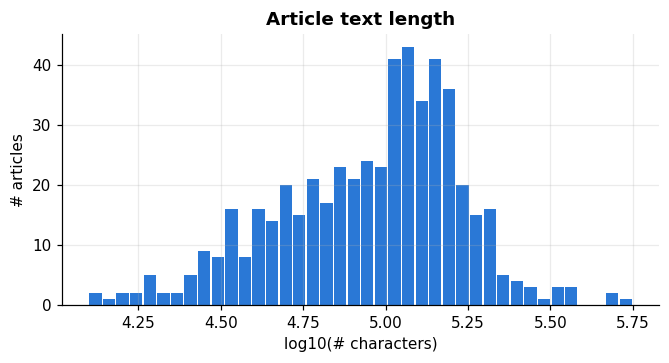

In [11]:
t0 = time.time()
train_texts = load_texts(train_art, source="both", cache_path="/content/train_texts.json")
print(f"{len(train_texts)} articles in {time.time() - t0:.0f}s")
train_art["n_chars"] = train_art.article_id.map(lambda a: len(train_texts[a]))
print(train_art.n_chars.describe().round(0))
print("empty texts:", (train_art.n_chars == 0).sum())

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.log10(train_art.n_chars.clip(lower=1)), bins=40, color=C["bar"], rwidth=.9)
ax.set_xlabel("log10(# characters)"); ax.set_ylabel("# articles"); ax.set_title("Article text length")
plt.show()

In [12]:
def found_in_text(row):
    text = train_texts.get(row.article_id, "").lower()
    return row.dataset_id.replace("https://doi.org/", "").lower() in text

gold["found"] = gold.apply(found_in_text, axis=1)
print(gold.groupby(["id_kind", "type"])["found"].mean().round(3))
print("\nshare of gold ids present in the text:", round(gold.found.mean(), 3))
gold[~gold.found].head(10)

id_kind    type     
Accession  Primary      1.000
           Secondary    1.000
DOI        Primary      0.837
           Secondary    0.964
Name: found, dtype: float64

share of gold ids present in the text: 0.946


,article_id,dataset_id,type,id_kind,found
19,10.1016_j.ast.2022.107401,https://doi.org/10.17862/cranfield.rd.19146182,Primary,DOI,False
20,10.1016_j.ast.2022.107401,https://doi.org/10.17862/cranfield.rd.19146182.v1,Primary,DOI,False
21,10.1016_j.cpc.2024.109087,https://doi.org/10.17632/9gr6pxhfjm,Primary,DOI,False
24,10.1016_j.ecolind.2021.107934,https://doi.org/10.6073/pasta/be42bb841e696b7bcad9957aed33db5e,Secondary,DOI,False
26,10.1016_j.fuel.2022.125768,https://doi.org/10.11583/dtu.20555586.v3,Primary,DOI,False
27,10.1016_j.jlp.2022.104761,https://doi.org/10.23642/usn.15134442,Primary,DOI,False
28,10.1016_j.jlp.2022.104761,https://doi.org/10.23642/usn.15134442.v1,Primary,DOI,False
29,10.1016_j.jobe.2023.107105,https://doi.org/10.5281/zenodo.8014149,Primary,DOI,False
38,10.1021_acs.jcim.9b01185,https://doi.org/10.5281/zenodo.3667633,Primary,DOI,False
52,10.1021_jacs.2c06519,https://doi.org/10.25377/sussex.21184705.v1,Primary,DOI,False


In [13]:
cands = build_candidates(train_texts, window=250, ref_start_fn=reference_start)
cands = cands[cands.article_id.isin(labels.article_id)]
lab_c = attach_gold(cands, gold)
uniq = lab_c.drop_duplicates(["article_id", "dataset_id"])
print(f"mentions: {len(cands)} | unique (article, id) candidates: {len(uniq)}")
summary = (uniq.groupby(["kind", "pattern"])["label"]
               .agg(n="size", datasets=lambda s: (s != "None").sum())
               .assign(precision=lambda d: (d.datasets / d.n).round(3))
               .sort_values("n", ascending=False))
summary.head(25)

mentions: 32412 | unique (article, id) candidates: 20341


n  datasets  precision
kind      pattern                            
DOI       10.1016   2956         0      0.000
          10.1038   1573         0      0.000
          10.1111   1229         0      0.000
          10.1093   1133         0      0.000
          10.1007   1069         0      0.000
          10.1002    935         0      0.000
          10.1371    724         0      0.000
Accession GenBank    693        27      0.039
DOI       10.1186    664         0      0.000
          10.1021    495         0      0.000
          10.1029    392         0      0.000
          10.1073    357         0      0.000
          10.1126    352         0      0.000
          10.5194    314         0      0.000
          10.13039   265         0      0.000
          10.1128    260         0      0.000
          10.1175    192         0      0.000
          10.1101    185         0      0.000
          10.1039    178         0      0.000
          10.3389    177         0      0.000
          10.1080    176         0      0.000
Accession UniProt    171        13      0.076
DOI       10.1107    147         0      0.000
          10.3390    145         0      0.000
          10.1098    138         0      0.000

In [14]:
cand_pairs = set(zip(uniq.article_id, uniq.dataset_id))
gold_pairs = set(zip(gold.article_id, gold.dataset_id))
print("recall upper bound (gold ids found by regex):", round(len(cand_pairs & gold_pairs) / len(gold_pairs), 3))
print("raw precision (if we predicted every candidate):", round((uniq.label != "None").mean(), 3))

recall upper bound (gold ids found by regex): 0.805
raw precision (if we predicted every candidate): 0.028


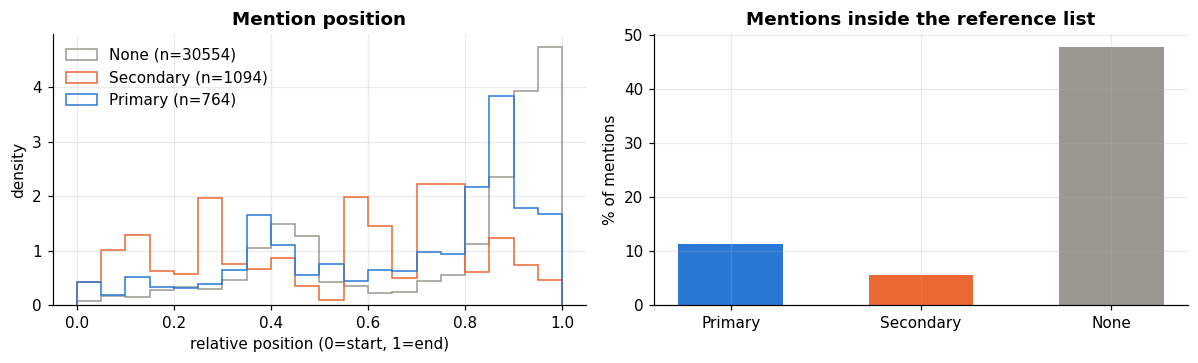

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for lbl in ["None", "Secondary", "Primary"]:
    sub = lab_c[lab_c.label == lbl]
    ax[0].hist(sub.rel_pos, bins=20, range=(0, 1), histtype="step", lw=2, color=C[lbl], density=True,
               label=f"{lbl} (n={len(sub)})", ls="--" if lbl == "None" else "-")
ax[0].set_xlabel("relative position (0=start, 1=end)"); ax[0].set_ylabel("density")
ax[0].set_title("Mention position"); ax[0].legend(frameon=False)

ref = lab_c.groupby("label")["in_references"].mean().reindex(["Primary", "Secondary", "None"])
ax[1].bar(ref.index, ref.values * 100, color=[C[k] for k in ref.index], width=.55)
ax[1].set_ylabel("% of mentions"); ax[1].set_title("Mentions inside the reference list")
plt.tight_layout(); plt.show()

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

ds = lab_c[lab_c.label.isin(["Primary", "Secondary"])]
cv = CountVectorizer(stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
X = cv.fit_transform(ds.context)
vocab = np.array(cv.get_feature_names_out())
p = np.asarray(X[(ds.label == "Primary").values].sum(0)).ravel() + 1
s = np.asarray(X[(ds.label == "Secondary").values].sum(0)).ravel() + 1
log_ratio = np.log((p / p.sum()) / (s / s.sum()))
order = np.argsort(log_ratio)
pd.DataFrame({"Secondary-leaning": vocab[order[:20]], "Primary-leaning": vocab[order[::-1][:20]]})

,Secondary-leaning,Primary-leaning
0,geod,dryad
1,flagellar,liaoning
2,pair,diffraction
3,afp,shorebird
4,alb,curlew
5,char,material
6,saliva,vaojlj
7,colspan,eastern
8,plate,october
9,align,accessibility


In [17]:
for t in ["Primary", "Secondary"]:
    print(f"===== {t} examples =====")
    for ctx in ds[ds.label == t].sample(3, random_state=1).context:
        print("...", ctx[150:400], "...\n")

===== Primary examples =====
... 4 in: Cryopreservation of orchid seeds through rapid and step freezing methods. F1000Research. 2018 10.5256/f1000research.13622.d194236 10.5256/f1000research.14799.r33998 Referee response for version 1 Hunyadi Éva Borbélyné 1 Referee 1 Research Insti ...

... ons are available in Supplementary Material of this article available on Dryad at http://dx.doi.org/10.5061/dryad.739bs, Appendix S1. Scenario I.-We began simulations with the null scenario of a single, unstructured population or species (Fig. 1a), u ...

... m.nih.gov/biosample/SAMN16233656 SAMN16233656 , https://www.ncbi.nlm.nih.gov/biosample/SAMN16233657 SAMN16233657 , https://www.ncbi.nlm.nih.gov/biosample/SAMN16233658 SAMN16233658 , https://www.ncbi.nlm.nih.gov/biosample/SAMN16233659 SAMN16233659 , h ...

===== Secondary examples =====
... .ebi.ac.uk/chembl/compound_report_card/CHEMBL561/ https://www.ebi.ac.uk/chembl/compound_report_card/CHEMBL561/ Lomefloxacin 4 (approved) C17H19F2N3O3 Plate 